# Sleep Staging — 11: Comparación final y selección del modelo

**Objetivo:** cerrar la etapa experimental comparando los modelos principales sobre los mismos epochs del holdout y consolidar la selección del modelo final.

La notebook no entrena modelos nuevos. Utiliza los artefactos generados en NB4–NB10 para:

- comparar Random Forest, LightGBM, 1D-CNN y CNN + BiGRU;
- analizar el desempeño por etapa de sueño;
- revisar la mejora del modelo temporal por sujeto;
- visualizar un hipnograma representativo;
- dejar documentada la selección final del modelo temporal.


---
## 1. Setup


In [3]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

warnings.filterwarnings("ignore")

RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Predicciones previas
BASELINE_PRED_PATH = RESULTS_DIR / "baseline_holdout_predictions.parquet"
BOOSTING_PRED_PATH = RESULTS_DIR / "boosting_holdout_predictions.parquet"
CNN_PRED_PATH = RESULTS_DIR / "dl_cnn_holdout_predictions.parquet"
TEMPORAL_PRED_PATH = RESULTS_DIR / "dl_end_to_end_predictions.parquet"

# Resultados de NB9 y NB10
CONTEXT_VALIDATION_PATH = RESULTS_DIR / "dl_context_size_validation.csv"
CONTEXT_TEST_PATH = RESULTS_DIR / "dl_context_size_test.csv"
FINETUNE_COMPARISON_PATH = RESULTS_DIR / "dl_end_to_end_comparison.csv"
FINETUNE_HISTORY_PATH = RESULTS_DIR / "dl_end_to_end_training_history.csv"

# Salidas de NB11
GLOBAL_PATH = RESULTS_DIR / "final_model_comparison.csv"
PER_STAGE_PATH = RESULTS_DIR / "final_model_per_stage.csv"
PER_SUBJECT_PATH = RESULTS_DIR / "final_model_per_subject.csv"
SELECTION_PATH = RESULTS_DIR / "final_model_selection.json"

GLOBAL_FIG_PATH = FIGURES_DIR / "final_model_macro_f1.png"
SUBJECT_FIG_PATH = FIGURES_DIR / "final_temporal_subject_delta.png"
HYPNOGRAM_PATH = FIGURES_DIR / "final_hypnogram_comparison.png"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

required_paths = [
    BASELINE_PRED_PATH,
    BOOSTING_PRED_PATH,
    CNN_PRED_PATH,
    TEMPORAL_PRED_PATH,
    CONTEXT_VALIDATION_PATH,
    CONTEXT_TEST_PATH,
    FINETUNE_COMPARISON_PATH,
    FINETUNE_HISTORY_PATH,
]

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Faltan artefactos necesarios. Ejecutá NB4–NB10 antes de NB11:\n"
        + "\n".join(f"- {path}" for path in missing)
    )

print("Setup completado.")


Setup completado.


---
## 2. Alineación del holdout

El modelo temporal no puede generar predicciones para algunos epochs ubicados en los bordes de cada secuencia o alrededor de discontinuidades.

Para que la comparación sea justa, los cuatro modelos se evalúan únicamente sobre los epochs para los cuales existe una predicción temporal válida. La alineación se realiza por sujeto, índice original y tiempo de inicio.


In [4]:
baseline_pred = pd.read_parquet(BASELINE_PRED_PATH)
boosting_pred = pd.read_parquet(BOOSTING_PRED_PATH)
cnn_pred = pd.read_parquet(CNN_PRED_PATH)
temporal_pred = pd.read_parquet(TEMPORAL_PRED_PATH).rename(
    columns={"y_pred_baseline": "y_pred"}
)

JOIN_COLS = [
    "subject",
    "source_epoch_index",
    "recording_onset_s",
]

def prepare_epoch_model(df, pred_name):
    required = JOIN_COLS + ["y_true", "y_pred"]
    missing_cols = [col for col in required if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Faltan columnas en {pred_name}: {missing_cols}"
        )

    return (
        df[required]
        .rename(columns={"y_pred": pred_name})
        .copy()
    )

baseline_cmp = prepare_epoch_model(
    baseline_pred,
    "pred_random_forest",
)

boosting_cmp = prepare_epoch_model(
    boosting_pred,
    "pred_lightgbm",
)

cnn_cmp = prepare_epoch_model(
    cnn_pred,
    "pred_cnn",
)

temporal_required = JOIN_COLS + [
    "y_true",
    "y_pred",
    "is_transition",
]

missing_temporal = [
    col for col in temporal_required
    if col not in temporal_pred.columns
]

if missing_temporal:
    raise ValueError(
        f"Faltan columnas en predicciones temporales: {missing_temporal}"
    )

comparison_df = (
    temporal_pred[temporal_required]
    .rename(columns={"y_pred": "pred_temporal"})
    .merge(
        baseline_cmp,
        on=JOIN_COLS,
        how="inner",
        suffixes=("", "_rf"),
        validate="one_to_one",
    )
    .merge(
        boosting_cmp,
        on=JOIN_COLS,
        how="inner",
        suffixes=("", "_lgbm"),
        validate="one_to_one",
    )
    .merge(
        cnn_cmp,
        on=JOIN_COLS,
        how="inner",
        suffixes=("", "_cnn"),
        validate="one_to_one",
    )
)

label_cols = [
    "y_true",
    "y_true_rf",
    "y_true_lgbm",
    "y_true_cnn",
]

for col in label_cols[1:]:
    if not np.array_equal(
        comparison_df["y_true"].to_numpy(),
        comparison_df[col].to_numpy(),
    ):
        raise ValueError(
            f"Las etiquetas no coinciden después del merge: {col}"
        )

comparison_df = comparison_df.drop(
    columns=label_cols[1:]
)

print(f"Epochs comparables: {len(comparison_df):,}")
print(f"Sujetos:            {comparison_df['subject'].nunique()}")
display(comparison_df.head())


Epochs comparables: 26,446
Sujetos:            30


,subject,source_epoch_index,recording_onset_s,y_true,pred_temporal,is_transition,pred_random_forest,pred_lightgbm,pred_cnn
0,SN010,3,90.0,0,0,False,0,0,0
1,SN010,4,120.0,0,0,False,0,0,0
2,SN010,5,150.0,0,0,False,0,0,0
3,SN010,6,180.0,0,0,False,0,0,0
4,SN010,7,210.0,0,0,False,0,0,0


---
## 3. Comparación global

La métrica principal sigue siendo **Macro-F1**, ya que el problema presenta desbalance entre etapas de sueño.

Además se reportan accuracy y balanced accuracy.


In [5]:
MODEL_COLUMNS = {
    "Random Forest": "pred_random_forest",
    "LightGBM": "pred_lightgbm",
    "1D-CNN": "pred_cnn",
    "CNN + BiGRU | 5 epochs": "pred_temporal",
}

global_rows = []

for model_name, pred_col in MODEL_COLUMNS.items():
    global_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(
            comparison_df["y_true"],
            comparison_df[pred_col],
        ),
        "balanced_accuracy": balanced_accuracy_score(
            comparison_df["y_true"],
            comparison_df[pred_col],
        ),
        "macro_f1": f1_score(
            comparison_df["y_true"],
            comparison_df[pred_col],
            average="macro",
        ),
        "n_epochs": len(comparison_df),
        "n_subjects": comparison_df["subject"].nunique(),
    })

global_comparison = (
    pd.DataFrame(global_rows)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

global_comparison.to_csv(
    GLOBAL_PATH,
    index=False,
)

display(global_comparison.round(4))


,model,accuracy,balanced_accuracy,macro_f1,n_epochs,n_subjects
0,CNN + BiGRU | 5 epochs,0.7833,0.7804,0.7673,26446,30
1,1D-CNN,0.7430,0.7529,0.7348,26446,30
2,LightGBM,0.7403,0.7322,0.7210,26446,30
3,Random Forest,0.7334,0.7036,0.7000,26446,30


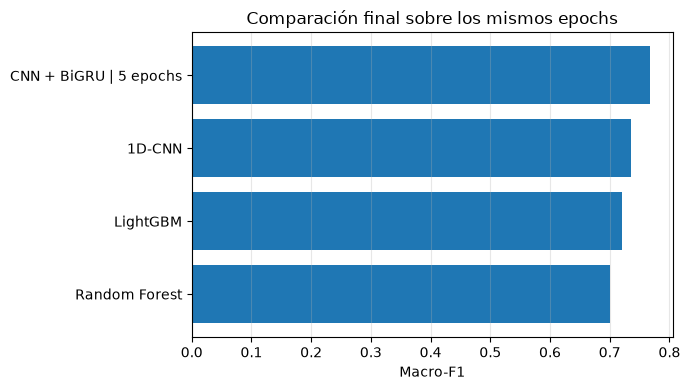

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

plot_df = global_comparison.sort_values(
    "macro_f1",
    ascending=True,
)

ax.barh(
    plot_df["model"],
    plot_df["macro_f1"],
)

ax.set_xlabel("Macro-F1")
ax.set_title("Comparación final sobre los mismos epochs")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig(
    GLOBAL_FIG_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.show()


---
## 4. Desempeño por etapa de sueño

Se compara el F1 de cada modelo para W, N1, N2, N3 y REM sobre exactamente el mismo subconjunto del holdout.


In [7]:
stage_rows = []

for model_name, pred_col in MODEL_COLUMNS.items():
    for class_idx, stage_name in STAGE_MAP.items():
        stage_rows.append({
            "model": model_name,
            "stage": stage_name,
            "f1": f1_score(
                comparison_df["y_true"] == class_idx,
                comparison_df[pred_col] == class_idx,
                zero_division=0,
            ),
            "support": int(
                (comparison_df["y_true"] == class_idx).sum()
            ),
        })

per_stage = pd.DataFrame(stage_rows)

per_stage.to_csv(
    PER_STAGE_PATH,
    index=False,
)

stage_pivot = (
    per_stage
    .pivot(
        index="stage",
        columns="model",
        values="f1",
    )
    .reindex(STAGE_NAMES)
)

display(stage_pivot.round(4))


model,1D-CNN,CNN + BiGRU | 5 epochs,LightGBM,Random Forest
stage,,,,
W,0.7817,0.8010,0.7836,0.7851
N1,0.4707,0.5147,0.4318,0.3806
N2,0.7540,0.8058,0.7580,0.7594
N3,0.8382,0.8501,0.8169,0.7966
REM,0.8295,0.8651,0.8147,0.7783


---
## 5. Mejora temporal por sujeto

Además de la métrica global, se analiza si el beneficio del contexto temporal aparece de forma consistente entre sujetos.

Para cada uno de los 30 sujetos del holdout se calcula Macro-F1 para la CNN aislada y para CNN + BiGRU. Luego se obtiene la diferencia entre ambos modelos.


In [8]:
subject_rows = []

for subject, subject_df in comparison_df.groupby("subject"):
    cnn_f1 = f1_score(
        subject_df["y_true"],
        subject_df["pred_cnn"],
        average="macro",
        zero_division=0,
    )

    temporal_f1 = f1_score(
        subject_df["y_true"],
        subject_df["pred_temporal"],
        average="macro",
        zero_division=0,
    )

    subject_rows.append({
        "subject": subject,
        "n_epochs": len(subject_df),
        "cnn_macro_f1": cnn_f1,
        "temporal_macro_f1": temporal_f1,
        "delta_macro_f1": temporal_f1 - cnn_f1,
    })

per_subject = (
    pd.DataFrame(subject_rows)
    .sort_values("delta_macro_f1")
    .reset_index(drop=True)
)

per_subject.to_csv(
    PER_SUBJECT_PATH,
    index=False,
)

n_improved = int(
    (per_subject["delta_macro_f1"] > 0).sum()
)

n_worse = int(
    (per_subject["delta_macro_f1"] < 0).sum()
)

subject_summary = pd.DataFrame({
    "metric": [
        "subjects",
        "improved",
        "worse",
        "mean_delta_macro_f1",
        "median_delta_macro_f1",
        "min_delta_macro_f1",
        "max_delta_macro_f1",
    ],
    "value": [
        len(per_subject),
        n_improved,
        n_worse,
        per_subject["delta_macro_f1"].mean(),
        per_subject["delta_macro_f1"].median(),
        per_subject["delta_macro_f1"].min(),
        per_subject["delta_macro_f1"].max(),
    ],
})

display(subject_summary.round(4))
display(per_subject.round(4))


,metric,value
0,subjects,30.0000
1,improved,28.0000
2,worse,2.0000
3,mean_delta_macro_f1,0.0350
4,median_delta_macro_f1,0.0360
5,min_delta_macro_f1,-0.0290
6,max_delta_macro_f1,0.0977


,subject,n_epochs,cnn_macro_f1,temporal_macro_f1,delta_macro_f1
0,SN069,731,0.8331,0.8041,-0.0290
1,SN073,885,0.6893,0.6825,-0.0068
2,SN028,887,0.8357,0.8463,0.0105
3,SN078,868,0.7544,0.7652,0.0108
4,SN010,918,0.6830,0.6973,0.0143
5,SN128,920,0.7497,0.7658,0.0161
6,SN083,1081,0.7768,0.7948,0.0180
7,SN021,950,0.6724,0.6922,0.0199
8,SN122,839,0.8186,0.8388,0.0202
9,SN034,881,0.7532,0.7818,0.0286


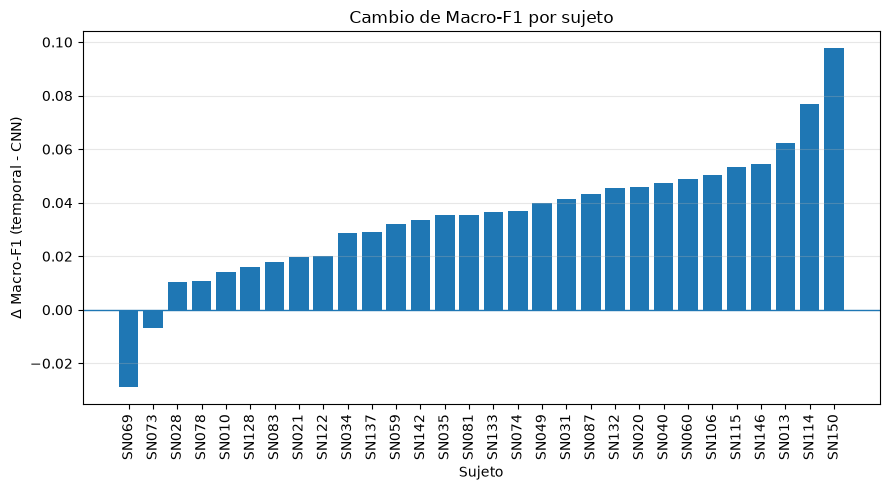

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

plot_subjects = per_subject.sort_values(
    "delta_macro_f1"
)

ax.bar(
    plot_subjects["subject"],
    plot_subjects["delta_macro_f1"],
)

ax.axhline(0, linewidth=1)
ax.set_ylabel("Δ Macro-F1 (temporal - CNN)")
ax.set_xlabel("Sujeto")
ax.set_title("Cambio de Macro-F1 por sujeto")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    SUBJECT_FIG_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.show()


---
## 6. Hipnograma de un sujeto representativo

Para evitar seleccionar manualmente un caso especialmente favorable, se elige el sujeto cuya mejora con contexto temporal está más cerca de la **mediana** de la mejora observada en el holdout.

Se comparan las etiquetas reales, la CNN por epoch y el modelo temporal.


In [10]:
median_delta = per_subject["delta_macro_f1"].median()

representative_subject = (
    per_subject.assign(
        distance_to_median=lambda df:
            (df["delta_macro_f1"] - median_delta).abs()
    )
    .sort_values("distance_to_median")
    .iloc[0]["subject"]
)

subject_df = (
    comparison_df[
        comparison_df["subject"] == representative_subject
    ]
    .sort_values("recording_onset_s")
    .reset_index(drop=True)
)

print(f"Sujeto seleccionado: {representative_subject}")
print(
    "Δ Macro-F1:",
    round(
        float(
            per_subject.loc[
                per_subject["subject"] == representative_subject,
                "delta_macro_f1",
            ].iloc[0]
        ),
        4,
    ),
)


Sujeto seleccionado: SN133
Δ Macro-F1: 0.0366


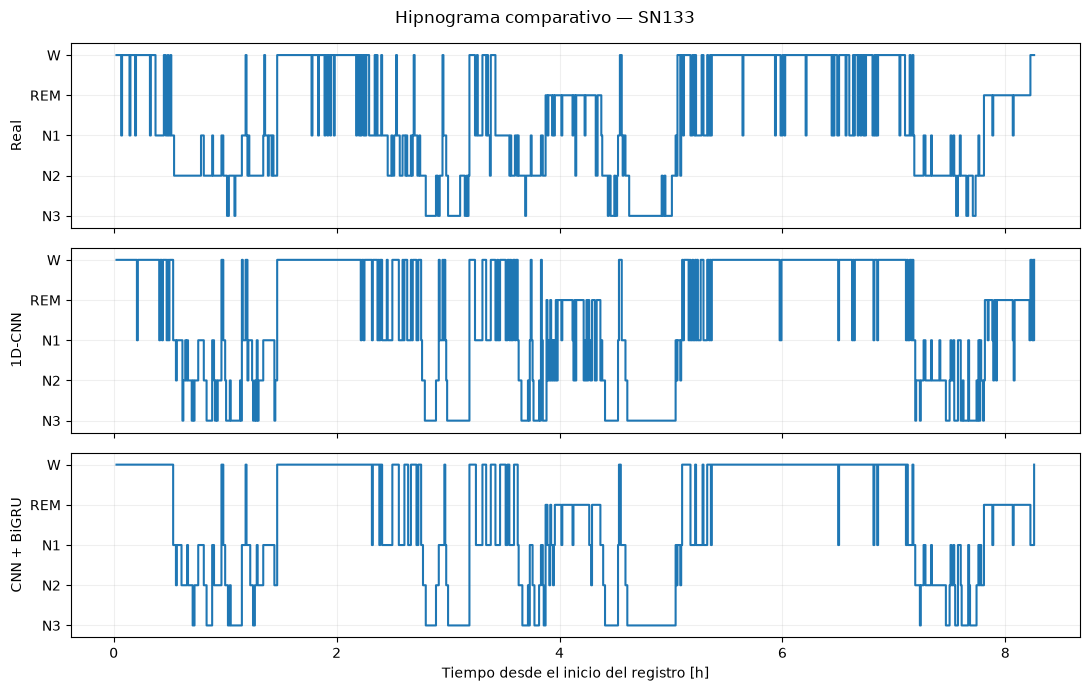

In [11]:
# Orden visual típico de un hipnograma:
# W arriba, luego REM, N1, N2 y N3.
HYPNO_MAP = {
    0: 0,  # W
    4: 1,  # REM
    1: 2,  # N1
    2: 3,  # N2
    3: 4,  # N3
}

HYPNO_LABELS = ["W", "REM", "N1", "N2", "N3"]

time_hours = (
    subject_df["recording_onset_s"].to_numpy()
    / 3600
)

y_true_plot = (
    subject_df["y_true"]
    .map(HYPNO_MAP)
    .to_numpy()
)

cnn_plot = (
    subject_df["pred_cnn"]
    .map(HYPNO_MAP)
    .to_numpy()
)

temporal_plot = (
    subject_df["pred_temporal"]
    .map(HYPNO_MAP)
    .to_numpy()
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(11, 7),
    sharex=True,
)

series = [
    ("Real", y_true_plot),
    ("1D-CNN", cnn_plot),
    ("CNN + BiGRU", temporal_plot),
]

for ax, (title, values) in zip(axes, series):
    ax.step(
        time_hours,
        values,
        where="post",
    )
    ax.set_yticks(range(len(HYPNO_LABELS)))
    ax.set_yticklabels(HYPNO_LABELS)
    ax.set_ylim(4.3, -0.3)
    ax.set_ylabel(title)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Tiempo desde el inicio del registro [h]")

fig.suptitle(
    f"Hipnograma comparativo — {representative_subject}"
)

plt.tight_layout()

fig.savefig(
    HYPNOGRAM_PATH,
    dpi=150,
    bbox_inches="tight",
)

plt.show()


---
## 7. Selección de tamaño de contexto y fine-tuning

La arquitectura final no se elige a partir del holdout.

Primero se revisa el tamaño de contexto seleccionado por **validation** en NB9. Luego se compara ese modelo congelado con el ajuste end-to-end de NB10 para comprobar si adaptar conjuntamente la CNN y la BiGRU aporta una mejora consistente.


In [12]:
context_validation = pd.read_csv(
    CONTEXT_VALIDATION_PATH
)

context_test = pd.read_csv(
    CONTEXT_TEST_PATH
)

finetune_comparison = pd.read_csv(
    FINETUNE_COMPARISON_PATH
)

finetune_history = pd.read_csv(
    FINETUNE_HISTORY_PATH
)

display(context_validation.round(4))
display(context_test.round(4))
display(finetune_comparison.round(4))

best_context_row = context_validation.loc[
    context_validation["val_macro_f1"].idxmax()
]

selected_context = int(
    best_context_row["context_size"]
)

frozen_val_macro_f1 = float(
    best_context_row["val_macro_f1"]
)

best_finetuned_val_macro_f1 = float(
    finetune_history["val_macro_f1"].max()
)

print(
    f"Contexto elegido por validation: "
    f"{selected_context} epochs"
)

print(
    f"Frozen validation Macro-F1: "
    f"{frozen_val_macro_f1:.4f}"
)

print(
    f"Mejor fine-tuned validation Macro-F1: "
    f"{best_finetuned_val_macro_f1:.4f}"
)


,context_size,seconds,best_epoch,val_accuracy,val_balanced_accuracy,val_macro_f1
0,3,90,13,0.7954,0.7840,0.7755
1,5,150,24,0.7952,0.7917,0.7816
2,7,210,10,0.7931,0.7894,0.7795


,context_size,seconds,accuracy,balanced_accuracy,macro_f1,n_epochs
0,3,90,0.7868,0.7827,0.7684,26446
1,5,150,0.7833,0.7804,0.7673,26446
2,7,210,0.7854,0.7859,0.7731,26446


,model,accuracy,balanced_accuracy,macro_f1,n_epochs
0,CNN + BiGRU congelado,0.7833,0.7804,0.7673,26446
1,CNN + BiGRU fine-tuned,0.7848,0.7840,0.7690,26446


Contexto elegido por validation: 5 epochs
Frozen validation Macro-F1: 0.7816
Mejor fine-tuned validation Macro-F1: 0.7783


---
## 8. Modelo final

La selección final prioriza el criterio de validation y la simplicidad del modelo.

Si el fine-tuning no mejora de forma consistente el resultado de validation, se conserva el encoder CNN congelado y la BiGRU entrenada sobre sus embeddings.


In [13]:
if best_finetuned_val_macro_f1 > frozen_val_macro_f1:
    selected_model = "CNN + BiGRU fine-tuned"
    selection_reason = (
        "El fine-tuning mejoró el Macro-F1 de validation."
    )
else:
    selected_model = (
        f"CNN congelada + BiGRU | {selected_context} epochs"
    )
    selection_reason = (
        "El fine-tuning no mejoró de forma consistente el "
        "Macro-F1 de validation, por lo que se mantiene la "
        "alternativa más simple y reproducible."
    )

final_selection = {
    "selected_model": selected_model,
    "context_size_epochs": selected_context,
    "context_seconds": selected_context * 30,
    "selection_metric": "validation_macro_f1",
    "frozen_validation_macro_f1": frozen_val_macro_f1,
    "best_finetuned_validation_macro_f1": (
        best_finetuned_val_macro_f1
    ),
    "reason": selection_reason,
}

with open(
    SELECTION_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        final_selection,
        file,
        indent=2,
        ensure_ascii=False,
    )

print(json.dumps(
    final_selection,
    indent=2,
    ensure_ascii=False,
))


{
  "selected_model": "CNN congelada + BiGRU | 5 epochs",
  "context_size_epochs": 5,
  "context_seconds": 150,
  "selection_metric": "validation_macro_f1",
  "frozen_validation_macro_f1": 0.7815841309555818,
  "best_finetuned_validation_macro_f1": 0.7783130113006935,
  "reason": "El fine-tuning no mejoró de forma consistente el Macro-F1 de validation, por lo que se mantiene la alternativa más simple y reproducible."
}


---
## 9. Conclusiones

La comparación sobre los mismos epochs del holdout muestra una mejora progresiva entre los enfoques evaluados. Random Forest obtuvo un Macro-F1 de 0.7000, LightGBM de 0.7210, la CNN de 0.7348 y CNN + BiGRU de 0.7673. Incorporar información de epochs vecinos mejoró el resultado respecto de clasificar cada segmento de forma independiente.

El beneficio del contexto temporal apareció en 28 de los 30 sujetos de test, con una mejora media de Macro-F1 de 0.0350 respecto de la CNN. La mejora se extendió a la mayoría de los registros, aunque en dos sujetos el desempeño bajó.

El modelo temporal mejoró el F1 de las cinco etapas respecto de la CNN y obtuvo el mejor resultado entre los cuatro modelos en N1, N2, N3 y REM. En W, Random Forest mantuvo una pequeña ventaja. N1 pasó de un F1 de 0.4707 a 0.5147, pero continúa siendo la etapa más difícil.

Se mantiene como modelo final la CNN congelada con BiGRU y una ventana de 5 epochs, seleccionada por su Macro-F1 de validation en NB9. El fine-tuning de NB10 no superó ese resultado. Con los experimentos realizados, el principal aporte fue incorporar contexto temporal; ampliar la ventana o ajustar conjuntamente la CNN no mostró una mejora clara según validation.